# 09 — Comparer les 3 jeux NPZ

Même `SeriesInstanceUID`, coupe médiane (index 12), 3 recettes :

| | communautaire | crop130 v1 | RGB 2.5D DICOM |
|---|---|---|---|
| chemin | `data/volumes.zip` | `data/crop130/` | `data/crop130_rgb25d/` |
| crop | FOV → 224 | 130 mm (ou 70 %) | 130 mm (ou 70 %) |
| profondeur | linspace 24 sur toute la pile | bande 20–80 %, linspace 24 | mêmes 24 centres |
| canaux | gray `(24, 224, 224)` | gray `(24, 224, 224)` | RGB `(24, 3, 224, 224)` = `k-1, k, k+1` DICOM |

Le canal **G** du RGB 2.5D doit ressembler au crop130 v1 (même centre `k`). **R** et **B** sont les voisins anatomiques, pas les voisins des 24 linspace.

In [1]:
from __future__ import annotations

from pathlib import Path
import io
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 120, "axes.grid": False})

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

CSV = ROOT / "data" / "csv"
OLD_ZIP = ROOT / "data" / "volumes.zip"
CROP = ROOT / "data" / "crop130"
RGB = ROOT / "data" / "crop130_rgb25d"
PLANES = ["Sagittal", "Coronal", "Axial"]
K = 12  # coupe centrale des 24

series = pd.read_csv(CSV / "train_series.csv")


def index_zips(folder: Path, glob: str) -> dict[str, zipfile.ZipFile]:
    out: dict[str, zipfile.ZipFile] = {}
    for p in sorted(folder.glob(glob)):
        z = zipfile.ZipFile(p)
        n_npz = 0
        for name in z.namelist():
            if name.endswith(".npz"):
                out[Path(name).stem] = z
                n_npz += 1
        print(f"{p.name}: {n_npz} npz  ({p.stat().st_size/1e9:.2f} Go)")
    return out


def load_npz(index: dict[str, zipfile.ZipFile], sid: str) -> np.ndarray:
    return np.load(io.BytesIO(index[sid].read(f"{sid}.npz")))["data"]


old_z = zipfile.ZipFile(OLD_ZIP)
old_sids = {Path(n).stem for n in old_z.namelist() if n.endswith(".npz")}
crop_idx = index_zips(CROP, "volumes_crop130_part*.zip")
rgb_idx = index_zips(RGB, "volumes_crop130_rgb25d_part*.zip")

print("communautaire", len(old_sids))
print("crop130      ", len(crop_idx))
print("rgb25d       ", len(rgb_idx))
print("intersection ", len(set(crop_idx) & set(rgb_idx) & old_sids))

volumes_crop130_part0.zip: 6611 npz  (6.37 Go)
volumes_crop130_part1.zip: 6608 npz  (6.36 Go)
volumes_crop130_rgb25d_part0.zip: 4407 npz  (12.74 Go)
volumes_crop130_rgb25d_part1.zip: 4406 npz  (12.73 Go)
volumes_crop130_rgb25d_part2.zip: 4406 npz  (12.68 Go)
communautaire 24371
crop130       13219
rgb25d        13219
intersection  13219


In [2]:
common = set(crop_idx) & set(rgb_idx) & old_sids
rows = series[series.SeriesInstanceUID.isin(common)].copy()

# 1 serie par plan, etudes qui ont sag+cor+ax dans l'intersection
picks = []
for uid, g in rows.groupby("StudyInstanceUID"):
    by_plane = {}
    for plane in PLANES:
        gp = g[g.Anatomical_Plane == plane]
        if len(gp) == 0:
            break
        by_plane[plane] = gp.iloc[0].SeriesInstanceUID
    else:
        picks.append((uid, by_plane))
    if len(picks) >= 4:
        break

print("etudes 3 plans :", len(picks), "(on en montre", min(4, len(picks)), ")")
for uid, by_plane in picks:
    print(uid[-12:], {p: s[-8:] for p, s in by_plane.items()})

etudes 3 plans : 4 (on en montre 4 )
292195817260 {'Sagittal': '12333772', 'Coronal': '90476697', 'Axial': '26543265'}
075652399585 {'Sagittal': '69421711', 'Coronal': '13553280', 'Axial': '29424266'}
909909132231 {'Sagittal': '73479273', 'Coronal': '32921455', 'Axial': '55309042'}
434356622764 {'Sagittal': '73097711', 'Coronal': '67111543', 'Axial': '77121036'}


## Grille : communautaire | crop130 | RGB 2.5D

Pour le RGB, `imshow` des 3 canaux (R=`k-1`, G=`k`, B=`k+1`). Si R≈G≈B l’image paraît grise : les voisins DICOM sont très proches. Un léger liseré couleur = vrai écart d’une coupe.

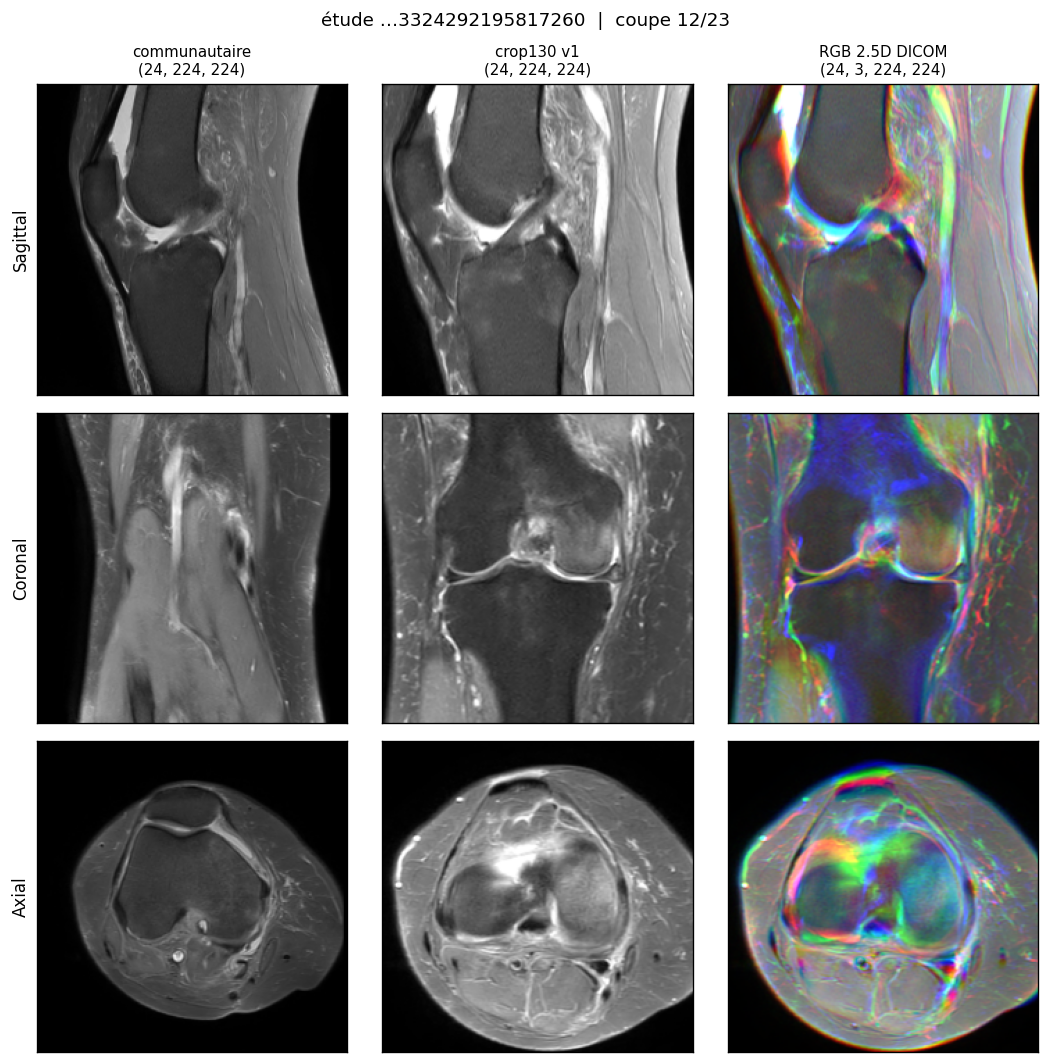

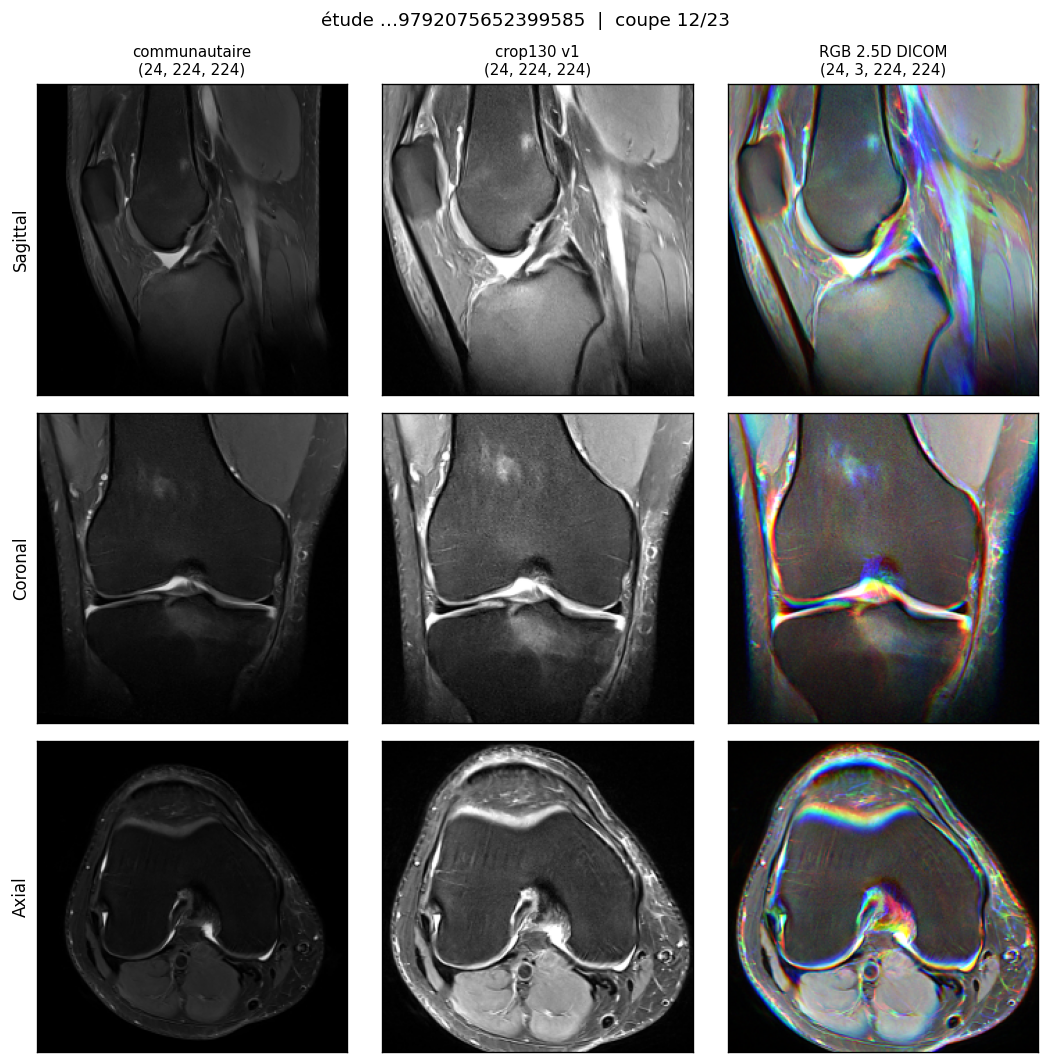

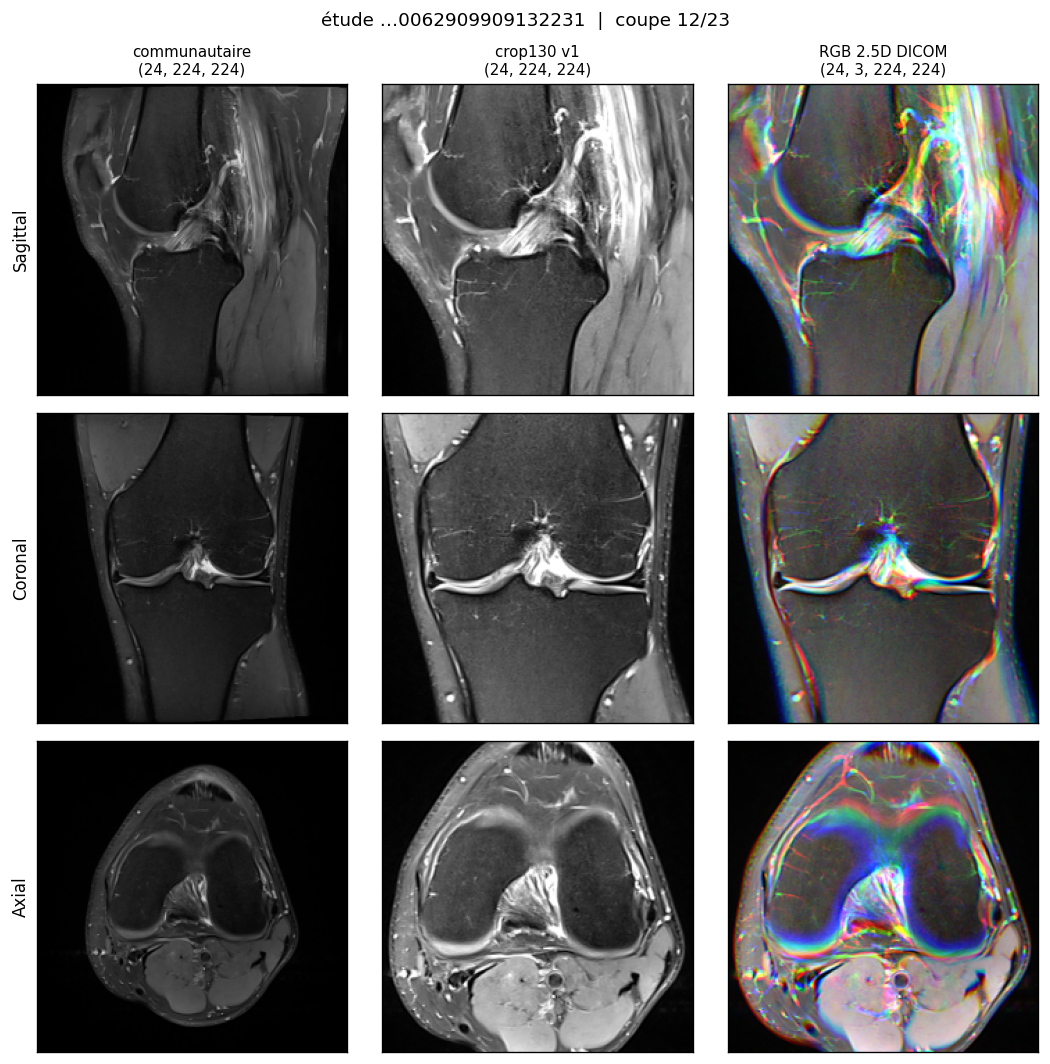

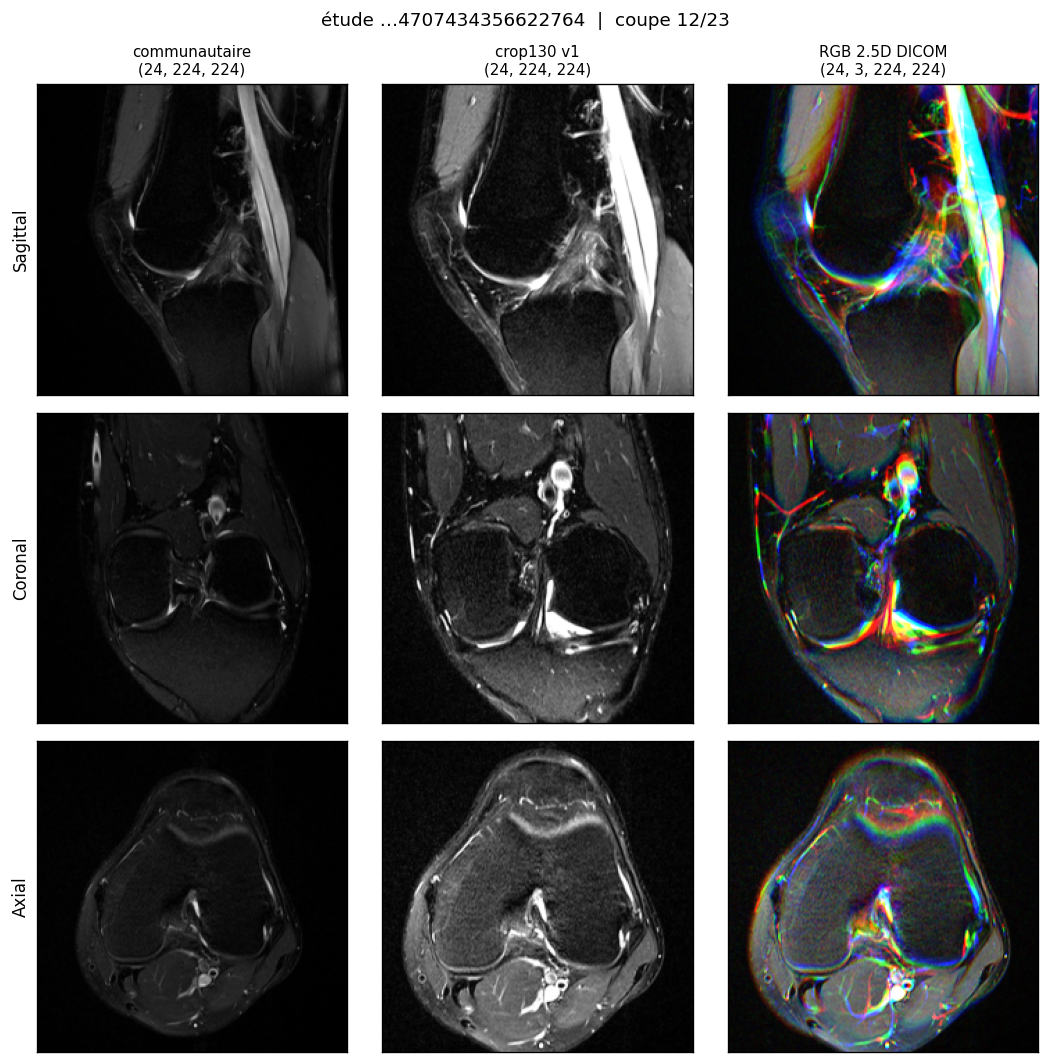

In [3]:
def as_gray(vol: np.ndarray, k: int) -> np.ndarray:
    sl = vol[k] if vol.ndim == 3 else vol[k, 1]
    return sl


def as_rgb(vol: np.ndarray, k: int) -> np.ndarray:
    if vol.ndim == 3:
        g = vol[k]
        return np.stack([g, g, g], axis=-1)
    return np.transpose(vol[k], (1, 2, 0))


titles = ["communautaire", "crop130 v1", "RGB 2.5D DICOM"]

for uid, by_plane in picks:
    fig, axes = plt.subplots(3, 3, figsize=(9, 9))
    fig.suptitle(f"étude …{uid[-16:]}  |  coupe {K}/23", fontsize=11)
    for i, plane in enumerate(PLANES):
        sid = by_plane[plane]
        vols = [
            np.load(io.BytesIO(old_z.read(f"{sid}.npz")))["data"],
            load_npz(crop_idx, sid),
            load_npz(rgb_idx, sid),
        ]
        for j, vol in enumerate(vols):
            ax = axes[i, j]
            if j < 2:
                ax.imshow(as_gray(vol, K), cmap="gray", vmin=0, vmax=255)
            else:
                ax.imshow(as_rgb(vol, K))
            if i == 0:
                ax.set_title(f"{titles[j]}\n{tuple(vol.shape)}", fontsize=9)
            if j == 0:
                ax.set_ylabel(plane, fontsize=10)
            ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout()
    plt.show()

## Canaux R / G / B vs crop130

G (centre) ≈ crop130. R et B = voisins DICOM ±1. `|R−G|` / `|B−G|` doivent être > 0 (sauf clamp au bord de pile).

sid 4091715412333772 rgb (24, 3, 224, 224) crop (24, 224, 224)
|G-crop130| 0.0
|R-G| 18.372011184692383 |B-G| 19.885025024414062


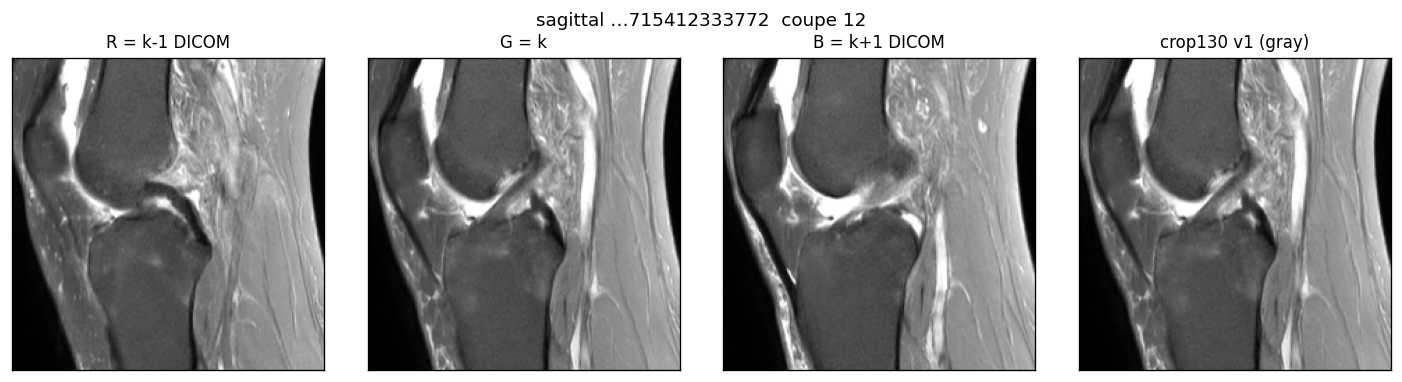

In [4]:
uid, by_plane = picks[0]
sid = by_plane["Sagittal"]
crop = load_npz(crop_idx, sid)
rgb = load_npz(rgb_idx, sid)
assert rgb.ndim == 4 and rgb.shape[1] == 3, rgb.shape

r, g, b = rgb[K, 0], rgb[K, 1], rgb[K, 2]
print("sid", sid[-16:], "rgb", rgb.shape, "crop", crop.shape)
print("|G-crop130|", float(np.abs(g.astype(np.float32) - crop[K].astype(np.float32)).mean()))
print("|R-G|", float(np.abs(r.astype(np.float32) - g.astype(np.float32)).mean()),
      "|B-G|", float(np.abs(b.astype(np.float32) - g.astype(np.float32)).mean()))

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, im, title in zip(
    axes,
    [r, g, b, crop[K]],
    ["R = k-1 DICOM", "G = k", "B = k+1 DICOM", "crop130 v1 (gray)"],
):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"sagittal …{sid[-12:]}  coupe {K}", fontsize=11)
plt.tight_layout()
plt.show()